In [10]:
import pandas as pd
import numpy as np
import sympy as sp
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from statsmodels.regression.quantile_regression import QuantReg


In [11]:
data = pd.read_csv("Calculus1.csv",sep=";")
# fundamental problem of cuasal inference 
data = data[data['Year'] == 1]
data=data.drop(columns=['Year'])
data=data.drop(columns=['Semster'])
data=data.drop(columns=['acadY'])
data=data.drop(columns=['Student'])
data.columns=data.columns.str.strip()
data=data.fillna(0)
data = pd.get_dummies(data, columns=['Department', 'Teacher', 'Location'], drop_first=True)
# استثناء المتغير المستقل Y
predictors = " + ".join(data.columns.difference(['Y']))

print(data.columns)

Index(['Unnamed: 0', 'Treatment', 'Y', 'Gender', 'HighSchool', 'Absence',
       'Failed', 'Incomplete', 'Department_1', 'Department_2', 'Department_3',
       'Department_4', 'Department_5', 'Department_6', 'Teacher_1',
       'Teacher_2', 'Teacher_3', 'Teacher_4', 'Teacher_5', 'Teacher_6',
       'Teacher_7', 'Teacher_8', 'Teacher_9', 'Teacher_10', 'Teacher_11',
       'Teacher_12', 'Teacher_13', 'Location_1', 'Location_2', 'Location_3'],
      dtype='object')


number of online student  1156
number of Face-to-Face student  1054
      Online  FaceToFace  Difference(Online-FaceToFace)
0.10    45.0        36.0                            9.0
0.25    58.0        48.0                           10.0
0.50    69.0        63.0                            6.0
0.75    79.0        80.0                           -1.0
0.90    86.0        90.0                           -4.0


C:\Users\HP\AppData\Local\Temp\ipykernel_12196\3056597936.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(groups, labels=labels, patch_artist=True)


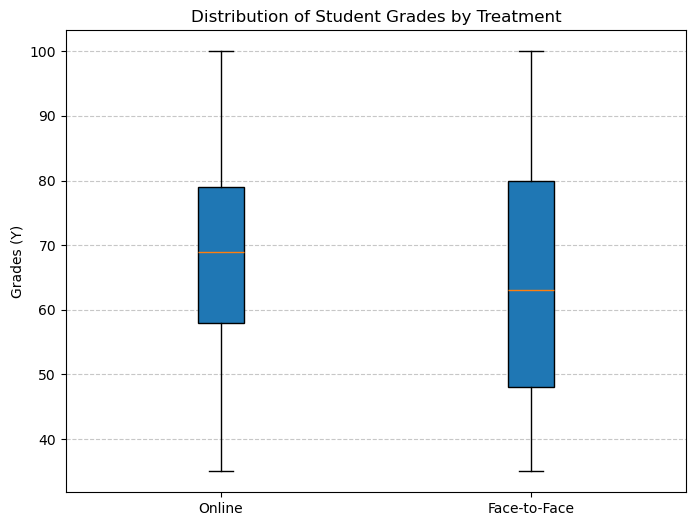

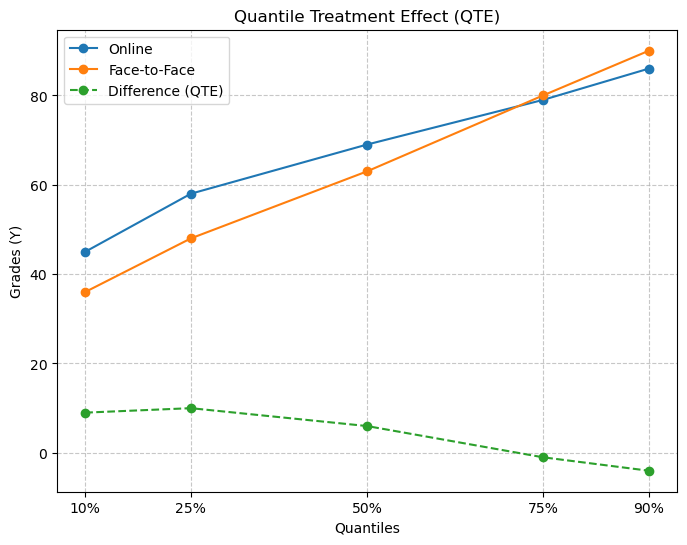

In [12]:
Online=data[data['Treatment']==1]['Y'].dropna()
FaceToFace=data[data['Treatment']==0]['Y'].dropna()
print("number of online student ", len(Online))
print("number of Face-to-Face student ", len(FaceToFace))
#توزيع y عبر quantiles مختلفة
# لاثبات الحاجة لاستخدام quantiles
quantiles=[0.1,0.25,0.5,0.75,0.9]
q_online=Online.quantile(quantiles)
q_FaceToFace=FaceToFace.quantile(quantiles)
comparison=pd.DataFrame({
    'Online':q_online,
    'FaceToFace':q_FaceToFace,
    'Difference(Online-FaceToFace)': q_online - q_FaceToFace
})
print(comparison)

groups = [Online, FaceToFace]
labels = ['Online', 'Face-to-Face']

# رسم Boxplot
plt.figure(figsize=(8,6))
plt.boxplot(groups, labels=labels, patch_artist=True)

plt.title('Distribution of Student Grades by Treatment')
plt.ylabel('Grades (Y)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

plt.figure(figsize=(8,6))
plt.plot(comparison.index, comparison['Online'], marker='o', label='Online')
plt.plot(comparison.index, comparison['FaceToFace'], marker='o', label='Face-to-Face')
plt.plot(comparison.index, comparison['Difference(Online-FaceToFace)'], 
         marker='o', linestyle='--', label='Difference (QTE)')

plt.title('Quantile Treatment Effect (QTE)')
plt.xlabel('Quantiles')
plt.ylabel('Grades (Y)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(quantiles, ['10%', '25%', '50%', '75%', '90%'])
plt.show()


In [13]:
# البداية 
# صيغة المعادلة مع Treatment + covariates + interactions(بدون Teacher في التفاعل)
formula = "Y ~ Treatment + HighSchool + Absence + Gender + Incomplete + Failed \
           + Department_1 + Department_2 + Department_3 + Department_4 + Department_5 + Department_6 \
           + Teacher_1 + Teacher_2 + Teacher_3 + Teacher_4 + Teacher_5 + Teacher_6 + Teacher_7 + Teacher_8 + Teacher_9 + Teacher_10 + Teacher_11 + Teacher_12 + Teacher_13 \
           + Location_1 + Location_2 + Location_3 \
           + Treatment*Department_1 + Treatment*Department_2 + Treatment*Department_3 + Treatment*Department_4 + Treatment*Department_5 + Treatment*Department_6 \
           + Treatment*Location_1 + Treatment*Location_2 + Treatment*Location_3 \
           + Treatment*Absence + Treatment*Failed + Treatment*HighSchool + Treatment*Gender + Treatment*Incomplete"

# نموذج Quantile Regression
model_qr = smf.quantreg(formula, data)

quantiles = [0.1, 0.25, 0.5, 0.75, 0.9]

plt.figure(figsize=(12, 8))

for idx, q in enumerate(quantiles, start=1):
    print(f"\n===== Quantile {q} =====")
    res = model_qr.fit(q=q)

    
    # نجيب المعاملات ونبني المعادلة كنص
    params = res.params
    equation = "Y = "
    for var, coef in params.items():
        sign = " + " if coef >= 0 else " - "
        equation += f"{sign}{abs(coef):.3f}*{var}"
    print("Equation:", equation)



===== Quantile 0.1 =====
Equation: Y =  - 8.625*Intercept + 10.285*Department_1[T.True] + 2.632*Department_2[T.True] - 0.267*Department_3[T.True] + 5.159*Department_4[T.True] + 12.891*Department_5[T.True] - 3.944*Department_6[T.True] + 0.509*Teacher_1[T.True] - 3.745*Teacher_2[T.True] - 1.838*Teacher_3[T.True] - 2.302*Teacher_4[T.True] - 1.838*Teacher_5[T.True] - 5.788*Teacher_6[T.True] - 3.732*Teacher_7[T.True] + 0.985*Teacher_8[T.True] - 4.820*Teacher_9[T.True] - 2.064*Teacher_10[T.True] + 0.078*Teacher_11[T.True] + 3.149*Teacher_12[T.True] + 6.553*Teacher_13[T.True] - 0.471*Location_1[T.True] - 6.627*Location_2[T.True] - 8.283*Location_3[T.True] - 6.686*Treatment - 5.408*Treatment:Department_1[T.True] - 4.935*Treatment:Department_2[T.True] - 3.404*Treatment:Department_3[T.True] - 3.898*Treatment:Department_4[T.True] - 17.939*Treatment:Department_5[T.True] - 1.880*Treatment:Department_6[T.True] + 1.503*Treatment:Location_1[T.True] + 3.502*Treatment:Location_2[T.True] + 6.957*Treatme

C:\Users\HP\anaconda3\Lib\site-packages\statsmodels\regression\quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (1000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +


Equation: Y =  - 54.586*Intercept + 10.382*Department_1[T.True] + 5.943*Department_2[T.True] + 2.946*Department_3[T.True] + 5.319*Department_4[T.True] + 9.669*Department_5[T.True] - 5.247*Department_6[T.True] + 1.654*Teacher_1[T.True] - 0.495*Teacher_2[T.True] + 1.039*Teacher_3[T.True] + 0.382*Teacher_4[T.True] - 1.249*Teacher_5[T.True] - 3.368*Teacher_6[T.True] - 2.274*Teacher_7[T.True] + 2.391*Teacher_8[T.True] - 2.014*Teacher_9[T.True] + 0.471*Teacher_10[T.True] + 2.406*Teacher_11[T.True] + 4.026*Teacher_12[T.True] + 1.012*Teacher_13[T.True] - 0.333*Location_1[T.True] - 1.711*Location_2[T.True] - 13.077*Location_3[T.True] + 57.600*Treatment - 1.479*Treatment:Department_1[T.True] - 3.911*Treatment:Department_2[T.True] - 4.611*Treatment:Department_3[T.True] + 0.684*Treatment:Department_4[T.True] + 3.782*Treatment:Department_5[T.True] + 5.958*Treatment:Department_6[T.True] + 1.442*Treatment:Location_1[T.True] - 1.475*Treatment:Location_2[T.True] + 11.908*Treatment:Location_3[T.True] + 

C:\Users\HP\anaconda3\Lib\site-packages\statsmodels\regression\quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (1000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +


Equation: Y =  - 42.905*Intercept + 7.669*Department_1[T.True] + 4.320*Department_2[T.True] + 7.511*Department_3[T.True] + 3.239*Department_4[T.True] + 6.217*Department_5[T.True] - 4.321*Department_6[T.True] + 3.810*Teacher_1[T.True] + 0.863*Teacher_2[T.True] + 1.571*Teacher_3[T.True] + 2.437*Teacher_4[T.True] + 0.668*Teacher_5[T.True] - 0.483*Teacher_6[T.True] - 1.201*Teacher_7[T.True] + 1.272*Teacher_8[T.True] + 1.052*Teacher_9[T.True] + 1.335*Teacher_10[T.True] + 4.545*Teacher_11[T.True] + 3.915*Teacher_12[T.True] + 4.019*Teacher_13[T.True] - 0.105*Location_1[T.True] - 2.430*Location_2[T.True] - 8.100*Location_3[T.True] + 55.822*Treatment - 1.847*Treatment:Department_1[T.True] - 3.835*Treatment:Department_2[T.True] - 9.164*Treatment:Department_3[T.True] + 2.621*Treatment:Department_4[T.True] + 6.025*Treatment:Department_5[T.True] + 1.266*Treatment:Department_6[T.True] + 1.169*Treatment:Location_1[T.True] + 2.430*Treatment:Location_2[T.True] + 6.837*Treatment:Location_3[T.True] + 1.2

<Figure size 1200x800 with 0 Axes>

In [14]:
# صيغة المعادلة مع Treatment + covariates + interactions (بدون Teacher في التفاعل)
formula = "Y ~ Treatment + HighSchool + Absence + Gender + Incomplete + Failed \
           + Department_1 + Department_2 + Department_3 + Department_4 + Department_5 + Department_6 \
           + Teacher_1 + Teacher_2 + Teacher_3 + Teacher_4 + Teacher_5 + Teacher_6 + Teacher_7 + Teacher_8 + Teacher_9 + Teacher_10 + Teacher_11 + Teacher_12 + Teacher_13 \
           + Location_1 + Location_2 + Location_3 \
           + Treatment*Department_1 + Treatment*Department_2 + Treatment*Department_3 + Treatment*Department_4 + Treatment*Department_5 + Treatment*Department_6 \
           + Treatment*Location_1 + Treatment*Location_2 + Treatment*Location_3 \
           + Treatment*Absence + Treatment*Failed + Treatment*HighSchool + Treatment*Gender + Treatment*Incomplete"

# نموذج Quantile Regression
model_qr = smf.quantreg(formula, data)

quantiles = [0.1, 0.25, 0.5, 0.75, 0.9]

plt.figure(figsize=(12, 8))

for idx, q in enumerate(quantiles, start=1):
    print(f"\n===== Quantile {q} =====")
    res = model_qr.fit(q=q)

    # معاملات
    params = res.params
    stderr = res.bse
    pvalues = res.pvalues
    conf_int = res.conf_int()

    # طباعة النتائج بشكل مرتب
    results_table = pd.DataFrame({
        "Beta": params,
        "StdErr": stderr,
        "p-value": pvalues,
        "CI_lower": conf_int[0],
        "CI_upper": conf_int[1]
    })
    print(results_table)
results_table.to_excel("results.xlsx", index=False)



===== Quantile 0.1 =====
                                     Beta     StdErr       p-value   CI_lower  \
Intercept                       -8.624966   9.044180  3.403681e-01 -26.361140   
Department_1[T.True]            10.285334   2.245632  4.909975e-06   5.881517   
Department_2[T.True]             2.631953   3.439759  4.442617e-01  -4.113618   
Department_3[T.True]            -0.267073   5.110259  9.583246e-01 -10.288594   
Department_4[T.True]             5.158627   2.451806  3.549238e-02   0.350491   
Department_5[T.True]            12.890955   5.436225  1.781230e-02   2.230196   
Department_6[T.True]            -3.943895   3.853879  3.062531e-01 -11.501580   
Teacher_1[T.True]                0.508529   2.732623  8.523872e-01  -4.850307   
Teacher_2[T.True]               -3.745094   3.126730  2.311387e-01  -9.876798   
Teacher_3[T.True]               -1.837590   3.097362  5.530585e-01  -7.911701   
Teacher_4[T.True]               -2.301680   3.529361  5.143723e-01  -9.222967   
Te

C:\Users\HP\anaconda3\Lib\site-packages\statsmodels\regression\quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (1000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +


                                     Beta    StdErr       p-value   CI_lower  \
Intercept                      -54.585596  6.198290  2.586436e-18 -66.740810   
Department_1[T.True]            10.382097  1.424708  4.412037e-13   7.588159   
Department_2[T.True]             5.942909  2.248628  8.279016e-03   1.533216   
Department_3[T.True]             2.945593  3.456376  3.941861e-01  -3.832566   
Department_4[T.True]             5.319083  1.575287  7.468886e-04   2.229851   
Department_5[T.True]             9.668791  3.371741  4.176007e-03   3.056608   
Department_6[T.True]            -5.246949  2.458244  3.291951e-02 -10.067711   
Teacher_1[T.True]                1.654443  1.800173  3.581734e-01  -1.875802   
Teacher_2[T.True]               -0.495271  2.070600  8.109794e-01  -4.555841   
Teacher_3[T.True]                1.038930  2.056708  6.135105e-01  -2.994397   
Teacher_4[T.True]                0.382478  2.240585  8.644719e-01  -4.011442   
Teacher_5[T.True]               -1.24871

C:\Users\HP\anaconda3\Lib\site-packages\statsmodels\regression\quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (1000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +


                                     Beta    StdErr       p-value   CI_lower  \
Intercept                      -42.905026  5.974291  9.428741e-13 -54.620966   
Department_1[T.True]             7.669347  1.289372  3.153949e-09   5.140813   
Department_2[T.True]             4.319540  2.008776  3.163914e-02   0.380210   
Department_3[T.True]             7.510784  3.103153  1.558638e-02   1.425317   
Department_4[T.True]             3.238709  1.406847  2.142369e-02   0.479798   
Department_5[T.True]             6.216710  3.104327  4.534516e-02   0.128940   
Department_6[T.True]            -4.321449  2.203884  5.002636e-02  -8.643395   
Teacher_1[T.True]                3.810346  1.619496  1.872175e-02   0.634418   
Teacher_2[T.True]                0.862693  1.863169  6.433930e-01  -2.791091   
Teacher_3[T.True]                1.570981  1.867752  4.003803e-01  -2.091792   
Teacher_4[T.True]                2.436858  2.039211  2.322176e-01  -1.562156   
Teacher_5[T.True]                0.66798

<Figure size 1200x800 with 0 Axes>

In [15]:
model_qr = smf.quantreg(formula, data)
quantiles = [0.1, 0.25, 0.5, 0.75, 0.9]

data_f2f = data.copy()
data_f2f["Treatment"] = 0

data_online = data.copy()
data_online["Treatment"] = 1

for q in quantiles:
    res = model_qr.fit(q=q)
    f2f_pred = res.predict(data_f2f)
    online_pred = res.predict(data_online)

    # أسماء الأعمدة حسب الكوانتايل
    col_f2f = f"q{int(q*100)}_f2f"
    col_online = f"q{int(q*100)}_online"

    # تخزين التوقعات لكل الطلاب
    data[col_f2f] = f2f_pred
    data[col_online] = online_pred

    print(f"\n===== Quantile {q} =====")
    print(f"stored")

    # طباعة النتائج لكل الطلاب
    results = pd.DataFrame({
        "F2F_Pred": f2f_pred,
        "Online_Pred": online_pred
    }).reset_index(drop=True)
    pd.set_option("display.max_rows", None) 
    print(results)

    # خط فاصل
    print("-" * 50)



===== Quantile 0.1 =====
stored
       F2F_Pred  Online_Pred
0     24.389287    17.798665
1     28.249537    24.149043
2     30.306926    33.342223
3     29.902003    31.464396
4     35.000001    33.240645
5     35.000001    22.066062
6     34.744335    33.529269
7     39.955780    41.784694
8     38.890895    41.426035
9     47.744350    47.147200
10    51.252104    58.359367
11    44.937860    50.745024
12    41.853317    38.431451
13    48.444569    45.143901
14    54.234699    55.840740
15    52.358905    53.057043
16    47.000459    29.434725
17    64.638176    66.378086
18    37.869805    44.105983
19    32.455009    42.398678
20    48.060089    53.272500
21    50.838295    50.321311
22    47.022797    55.245039
23    30.259442    29.927265
24    49.334094    44.232052
25    33.671481    34.580502
26    52.472654    46.520676
27    35.728517    33.319906
28    23.972800    27.064074
29    39.968123    45.533183
30    40.091762    39.021705
31    25.999905    25.985480
32    31.1

C:\Users\HP\anaconda3\Lib\site-packages\statsmodels\regression\quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (1000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +



===== Quantile 0.5 =====
stored
       F2F_Pred  Online_Pred
0     28.075795    49.653900
1     29.605114    44.694613
2     50.295989    57.989263
3     32.733518    53.059000
4     49.594829    57.122678
5     48.022614    60.498696
6     48.183891    53.925676
7     53.282298    58.601156
8     54.384143    64.506808
9     73.707655    76.582651
10    83.383486    79.882004
11    67.444709    67.842667
12    54.865737    60.664753
13    66.909396    69.236002
14    74.887637    73.803318
15    72.774402    71.885367
16    66.413707    68.062236
17    92.233914    83.245068
18    47.488500    55.199709
19    41.662968    58.249620
20    56.346589    60.056742
21    65.719347    69.074147
22    64.801589    71.673203
23    35.781377    55.803319
24    63.032581    68.674938
25    42.234393    58.036307
26    71.064804    72.870098
27    50.219647    61.752101
28    45.047945    52.362341
29    53.096641    70.139368
30    47.309771    59.918298
31    30.348669    52.663600
32    44.1

C:\Users\HP\anaconda3\Lib\site-packages\statsmodels\regression\quantile_regression.py:191: IterationLimitWarning: Maximum number of iterations (1000) reached.
  warnings.warn("Maximum number of iterations (" + str(max_iter) +



===== Quantile 0.75 =====
stored
       F2F_Pred  Online_Pred
0     40.330950    61.041025
1     40.695450    52.194365
2     62.980273    68.533380
3     45.112723    65.200055
4     62.980118    66.496314
5     57.504521    66.572873
6     60.363775    62.525145
7     66.556763    68.529571
8     65.973999    76.114791
9     78.063116    82.480842
10    89.242309    88.330853
11    74.900144    74.815193
12    64.682656    66.750502
13    74.214988    76.734024
14    82.144994    82.038572
15    82.925601    78.726277
16    74.970965    71.903019
17    98.430991    88.341251
18    58.591913    62.202574
19    59.881521    68.149020
20    70.394985    71.040106
21    76.271188    76.148727
22    72.077325    80.036927
23    48.200164    67.489784
24    70.529808    71.953635
25    54.247503    69.844097
26    78.247099    75.839681
27    59.439486    64.381151
28    55.311906    64.487188
29    65.339929    76.881937
30    59.130777    69.926781
31    41.328977    62.893943
32    58.

In [16]:
data["delta_q10"] = data["q10_online"] - data["q10_f2f"]
data["delta_q25"] = data["q25_online"] - data["q25_f2f"]
data["delta_q50"] = data["q50_online"] - data["q50_f2f"]
data["delta_q75"] = data["q75_online"] - data["q75_f2f"]
data["delta_q90"] = data["q90_online"] - data["q90_f2f"]


In [17]:
summary = pd.DataFrame({
    "Diff": ["delta Q10","delta Q25","delta Q50","delta Q75","delta Q90"],
    "Mean": [data["delta_q10"].mean(),
             data["delta_q25"].mean(),
             data["delta_q50"].mean(),
             data["delta_q75"].mean(),
             data["delta_q90"].mean()],
    "SD": [data["delta_q10"].std(),
           data["delta_q25"].std(),
           data["delta_q50"].std(),
           data["delta_q75"].std(),
           data["delta_q90"].std()],
    "Median": [data["delta_q10"].median(),
               data["delta_q25"].median(),
               data["delta_q50"].median(),
               data["delta_q75"].median(),
               data["delta_q90"].median()],
    "Q25": [data["delta_q10"].quantile(0.25),
            data["delta_q25"].quantile(0.25),
            data["delta_q50"].quantile(0.25),
            data["delta_q75"].quantile(0.25),
            data["delta_q90"].quantile(0.25)],
    "Q75": [data["delta_q10"].quantile(0.75),
            data["delta_q25"].quantile(0.75),
            data["delta_q50"].quantile(0.75),
            data["delta_q75"].quantile(0.75),
            data["delta_q90"].quantile(0.75)],
    "Min": [data["delta_q10"].min(),
            data["delta_q25"].min(),
            data["delta_q50"].min(),
            data["delta_q75"].min(),
            data["delta_q90"].min()],
    "Max": [data["delta_q10"].max(),
            data["delta_q25"].max(),
            data["delta_q50"].max(),
            data["delta_q75"].max(),
            data["delta_q90"].max()]
})

print(summary)


        Diff      Mean        SD    Median       Q25       Q75        Min  \
0  delta Q10  2.440384  4.598680  2.742158  0.376561  5.174463 -35.965927   
1  delta Q25  2.162218  5.368468  1.401131 -1.866419  5.922390 -10.495709   
2  delta Q50  3.589652  7.788822  2.074989 -2.553533  9.193420 -11.182542   
3  delta Q75  3.142651  8.054989  1.863581 -3.121812  9.183640 -16.796315   
4  delta Q90  3.515158  7.859785  2.361957 -2.622954  9.040840 -20.236622   

         Max  
0  17.265123  
1  22.006713  
2  30.486065  
3  26.498596  
4  29.847601  


In [18]:

student = data.loc[66]
print(student[[
    "HighSchool","Gender","Absence","Failed","Incomplete",
    "Department","Location",
    "q10_f2f","q10_online","delta_q10",
    "q50_f2f","q50_online","delta_q50"
]])
print("-" * 50)
student = data.loc[1333]
print(student[[
    "HighSchool","Gender","Absence","Failed","Incomplete",
    "Department","Location",
    "q10_f2f","q10_online","delta_q10",
    "q50_f2f","q50_online","delta_q50"
]])
print("-" * 50)
student = data.loc[377]
print(student[[
    "HighSchool","Gender","Absence","Failed","Incomplete",
    "Department","Location",
    "q10_f2f","q10_online","delta_q10",
    "q50_f2f","q50_online","delta_q50"
]])
print("-" * 50)
student = data.loc[890]
print(student[[
    "HighSchool","Gender","Absence","Failed","Incomplete",
    "Department","Location",
    "q10_f2f","q10_online","delta_q10",
    "q50_f2f","q50_online","delta_q50"
]])
print("-" * 50)
student = data.loc[1988]
print(student[[
    "HighSchool","Gender","Absence","Failed","Incomplete",
    "Department","Location",
    "q10_f2f","q10_online","delta_q10",
    "q50_f2f","q50_online","delta_q50"
]])
print("-" * 50)


KeyError: "['Department', 'Location'] not in index"

In [ ]:
quantiles = [0.10, 0.25, 0.50, 0.75, 0.90]
B = 1000
np.random.seed(42)

formula = "Y ~ Treatment + HighSchool + Absence + Gender + Incomplete + Failed \
           + Department_1 + Department_2 + Department_3 + Department_4 + Department_5 + Department_6 \
           + Teacher_1 + Teacher_2 + Teacher_3 + Teacher_4 + Teacher_5 + Teacher_6 + Teacher_7 + Teacher_8 + Teacher_9 + Teacher_10 + Teacher_11 + Teacher_12 + Teacher_13 \
           + Location_1 + Location_2 + Location_3 \
           + Treatment*Department_1 + Treatment*Department_2 + Treatment*Department_3 + Treatment*Department_4 + Treatment*Department_5 + Treatment*Department_6 \
           + Treatment*Location_1 + Treatment*Location_2 + Treatment*Location_3 \
           + Treatment*Absence + Treatment*Failed + Treatment*HighSchool + Treatment*Gender + Treatment*Incomplete"

# جدول لتخزين النتائج
bootstrap_results = pd.DataFrame(columns=["Bootstrap", "delta_q10", "delta_q25", "delta_q50", "delta_q75", "delta_q90"])

# اللوب الخارجي
for b in range(1, B + 1):
    boot_data = data.sample(n=len(data), replace=True, random_state=b)

    # نسخ F2F و Online
    boot_f2f = boot_data.copy()
    boot_f2f["Treatment"] = 0
    boot_online = boot_data.copy()
    boot_online["Treatment"] = 1

    mean_deltas = []

    # اللوب الداخلي
    for q in quantiles:
        # بناء نموذج Quantile Regression بالـformula
        model = smf.quantreg(formula, boot_data)
        res = model.fit(q=q)

        # توقعات باستخدام نفس الأعمدة اللي بالـformula
        pred_f2f = res.predict(boot_f2f)
        pred_online = res.predict(boot_online)

        delta = pred_online - pred_f2f
        mean_deltas.append(delta.mean())

    bootstrap_results.loc[len(bootstrap_results)] = [b] + mean_deltas


print(bootstrap_results)

# حساب الإحصاءات العامة
summary_stats = bootstrap_results.drop(columns=["Bootstrap"]).describe(percentiles=[0.025, 0.5, 0.975]).T
print(summary_stats[["mean","std","2.5%","50%","97.5%","min","max"]])
